# TF-IDF + Logistic Regression

As a baseline model, we use a Term Frequency-Inverse Document Frequency representation
combined with a Logistic Regression classifier.

TF-IDF is a numerical statistic used in information retrieval and machine learning to measure a word's relevance to a document

#1. Importing requirements

In [1]:
#Import requirements
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import csv



#2. Cleaning and preparing raw data

In [3]:
#Path of the files
file_path = "/content/data.csv"
df = pd.read_csv(file_path)

#Remove special simbols
import re

def clean_text(text):

    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)

    return text

df["clean_text"] = (df["title"] + " " + df["text"]).apply(clean_text)

#Remove stopwords
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
all_words = " ".join(df["clean_text"]).split()
stopwords = set(ENGLISH_STOP_WORDS)
filtered_words = [
    word for word in all_words
    if word not in stopwords and len(word) > 2
]



#3. Tokenize and vectorize data

In [5]:
import nltk
nltk.download(['punkt_tab', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger', 'universal_tagset'], quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)


True

In [6]:

from nltk.tokenize import word_tokenize
from nltk.stem.wordnet import WordNetLemmatizer
from nltk.corpus import wordnet
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


# 1. Tokenization(NLTK)
tokenized = [word_tokenize(doc.lower()) for doc in filtered_words]

# 2. Lematization
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    """Convierts tag de NLTK to WordNet format"""
    return {'J': wordnet.ADJ, 'N': wordnet.NOUN,
            'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

def lemmatize_document(doc):
    """Lemmatize a whole doc (faster)"""
    tagged = nltk.pos_tag(doc)             #branding all document
    lemmatized = []
    for word, tag in tagged:
        pos = get_wordnet_pos(tag)
        lemma = lemmatizer.lemmatize(word, pos)
        lemmatized.append(lemma)
    return lemmatized

# Aply lemmatization
lemma_words = [lemmatize_document(doc) for doc in tokenized]

print(" Lemmatization complete. Examples:")
print(lemma_words[0][:15])

# 3. Reconstruct clean test for Keras
cleaned_texts = [' '.join(doc) for doc in lemma_words]

# 4. Numeric tokenazation (Keras)
tokenizer = Tokenizer(oov_token='<OOV>')
tokenizer.fit_on_texts(cleaned_texts)
sequences = tokenizer.texts_to_sequences(cleaned_texts)
#Padding the inputs for the model in order to have same lenght
max_seq_len = max(len(seq) for seq in sequences)
padded = pad_sequences(sequences, maxlen=max_seq_len, padding='pre')

print(f"\n Padding ended. Final shape: {padded.shape}")


 Lemmatization complete. Examples:
['budget']

 Padding ended. Final shape: (8588931, 2)


#4. Building, training model and evaluation

In [7]:
from sklearn.model_selection import train_test_split
# Train–Test Split
X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
# TF-IDF Vectorization with N-grams
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1,2),
    max_df=0.8,
    min_df=5
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF train shape:", X_train_tfidf.shape)

TF-IDF train shape: (31953, 214877)


In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [14]:
y_pred = model.predict(X_test_tfidf)
#Classification Report

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.99      0.98      0.98      3989
           1       0.98      0.99      0.98      4000

    accuracy                           0.98      7989
   macro avg       0.98      0.98      0.98      7989
weighted avg       0.98      0.98      0.98      7989



#5. Graphics

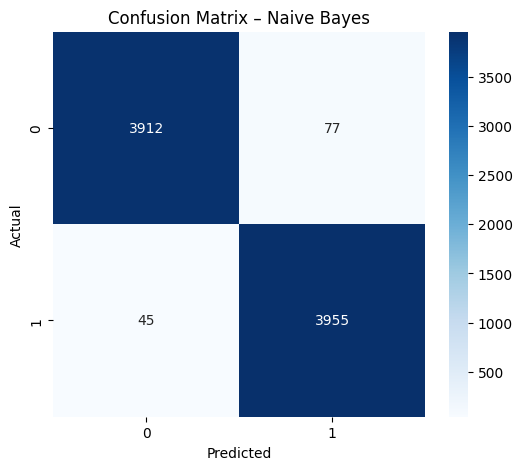

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

#Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Naive Bayes")

plt.show()


/tmp/ipykernel_232/3211328437.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_positive, x='coefficient', y='word', palette='Reds_r')


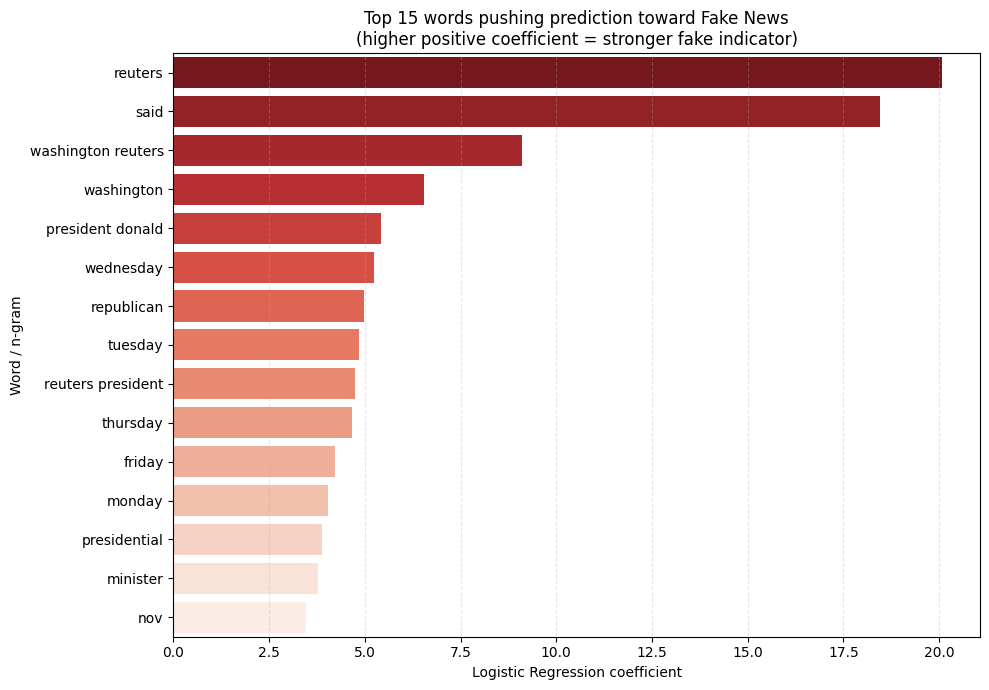

/tmp/ipykernel_232/3211328437.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_negative, x='coefficient', y='word', palette='Blues_r')


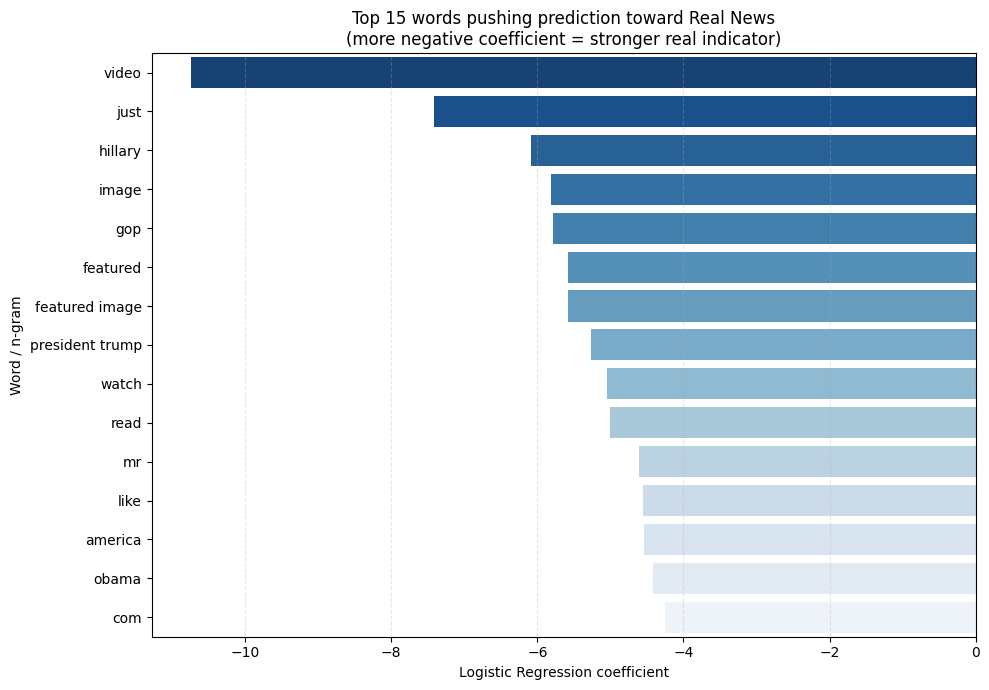

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# name of features
feature_names = tfidf.get_feature_names_out()

# Binary classification
coefs = model.coef_[0]

# Top 15 associate to FAKE news
top_positive_idx = np.argsort(coefs)[-15:][::-1]
top_positive_words = feature_names[top_positive_idx]
top_positive_coefs = coefs[top_positive_idx]

df_positive = pd.DataFrame({
    'word': top_positive_words,
    'coefficient': top_positive_coefs
})

# Graph
plt.figure(figsize=(10, 7))
sns.barplot(data=df_positive, x='coefficient', y='word', palette='Reds_r')
plt.title('Top 15 words pushing prediction toward Fake News\n(higher positive coefficient = stronger fake indicator)')
plt.xlabel('Logistic Regression coefficient')
plt.ylabel('Word / n-gram')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Top 15 associated to REAL news
top_negative_idx = np.argsort(coefs)[:15]
top_negative_words = feature_names[top_negative_idx]
top_negative_coefs = coefs[top_negative_idx]

df_negative = pd.DataFrame({
    'word': top_negative_words,
    'coefficient': top_negative_coefs
})

plt.figure(figsize=(10, 7))
sns.barplot(data=df_negative, x='coefficient', y='word', palette='Blues_r')
plt.title('Top 15 words pushing prediction toward Real News\n(more negative coefficient = stronger real indicator)')
plt.xlabel('Logistic Regression coefficient')
plt.ylabel('Word / n-gram')
plt.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()